# Survival Lab

We've looked at normal-linear regression and probit regression from a likelihood perspective, which yields two log-likelihoods:
$$
LL(\beta,\sigma) = - n \log( \sqrt{2\pi} ) - n \log(\sigma) - \frac{1}{2\sigma^2} \sum_{i=1}^n (y_i - x_i \beta)^2
$$
and
$$
LL(\beta) = \sum_{i=1}^N y_i \log(\Phi(x_i \cdot \beta/\sigma)) + (1-y_i) \log(1-\Phi(x_i \cdot \beta/\sigma)).
$$
This lab combines them by looking at **right-censored** survival data.

We are going to use the Metabric breast cancer dataset to predict how long someone survives after being treated for breast cancer. For the regressions that follow, include the following as numeric variables:

- 'Age at Diagnosis'
- 'Lymph nodes examined positive'
- 'Mutation Count'
- 'Tumor Size'

and the following as categorical variables (one-hot encode them):

- 'Chemotherapy'
- 'Hormone Therapy'
- 'Radio Therapy'
- 'Tumor Stage'

The outcome variable of interest is the log of `Overall Survival (Months)`, which we'll refer to as log-months.

1. Load the `./data/metabric.csv` data. Tabulate `Overall Survival Status` to see who is alive or dead at the time the study ends. Make a kernel density plot of `Overall Survival (Months)`, hued by `Overall Survival Status`, to see the difference between survival duration for those alive and those dead at the time the study ended. **Drop the observations for which `Tumor Stage` is zero.**
2. Use Scikit's `train_test_split` with a `test_size` of .2. There are two tempting -- but ultimately incorrect -- ways to handle the Survival Status issue:
    - Use the reported `Overall Survival (Months)` as the target variable
    - Drop everyone who is alive at the time the study ends
Run these flawed regressions and save the coefficients and test-set predictions. Explain clearly how the first option is an example of imputation and the second treats survival as missing data.
3. Derive the log-likelihood for a model where the normal density is used for log-months when the subject died during the study (and log-months is observed, as in linear-normal regression), and the survival probability based on the Normal distribution is used when the patient is alive when the study ends (and log-months is a latent variable, as in a binary probit).
4. We want to estimate the model in part 3. You can do this with the `lifelines` package's `LogNormalAFTFitter`, or use the code chunk below to extend StatsModels to estimate this kind of model.
5. Compare the coefficients and test-set predictions (be careful to keep an eye on the censoring) for the censored MLE and the two linear models. Can you identify any groups who receive systematically biased predictions from the imputation and missing data approaches? 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from statsmodels.base.model import GenericLikelihoodModel
from scipy.stats import norm

### 1. 

In [2]:
df = pd.read_csv("./data/metabric.csv")

print(df.shape)
df.head()

(1343, 14)


,Age at Diagnosis,Type of Breast Surgery,Cancer Type,Chemotherapy,Hormone Therapy,Lymph nodes examined positive,Mutation Count,Nottingham prognostic index,Overall Survival (Months),Overall Survival Status,Radio Therapy,TMB (nonsynonymous),Tumor Size,Tumor Stage
0,43.19,BREAST CONSERVING,Breast Cancer,NO,YES,0.0,2.0,4.020,84.633333,0:LIVING,YES,2.615035,10.0,1.0
1,48.87,MASTECTOMY,Breast Cancer,YES,YES,1.0,2.0,4.030,163.700000,1:DECEASED,NO,2.615035,15.0,2.0
2,47.68,MASTECTOMY,Breast Cancer,YES,YES,3.0,1.0,4.050,164.933333,0:LIVING,YES,1.307518,25.0,2.0
3,76.97,MASTECTOMY,Breast Cancer,YES,YES,8.0,2.0,6.080,41.366667,1:DECEASED,YES,2.615035,40.0,2.0
4,78.77,MASTECTOMY,Breast Cancer,NO,YES,0.0,4.0,4.062,7.800000,1:DECEASED,YES,5.230071,31.0,4.0


In [3]:
df["Overall Survival Status"].value_counts(dropna=False)

Overall Survival Status
1:DECEASED    768
0:LIVING      575
Name: count, dtype: int64

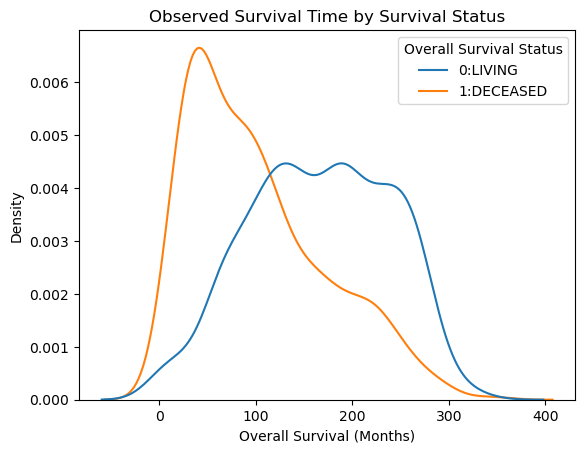

In [4]:
sns.kdeplot(
    data=df,
    x="Overall Survival (Months)",
    hue="Overall Survival Status",
    common_norm=False
)

plt.xlabel("Overall Survival (Months)")
plt.title("Observed Survival Time by Survival Status")
plt.show()

In [5]:
df = df[df["Tumor Stage"] != 0].copy()

There are 768 deceased patients and 575 living patients in the dataset. The KDE plot shows that deceased patients generally have shorter observed survival times, while living patients tend to have longer observed follow-up times. However, the survival times of living patients are right-censored. We only know that they survived at least as long as their recorded follow-up time, not their actual survival duration.

### 2. 

In [ ]:
numeric_cols = [
    "Age at Diagnosis",
    "Lymph nodes examined positive",
    "Mutation Count",
    "Tumor Size"
]

categorical_cols = [
    "Chemotherapy",
    "Hormone Therapy",
    "Radio Therapy",
    "Tumor Stage"
]

df["log_months"] = np.log(df["Overall Survival (Months)"])
df["event"] = (df["Overall Survival Status"] == "1:DECEASED").astype(int)
df[["log_months", "event"]].head()

,log_months,event
0,4.438328,0
1,5.098035,1
2,5.105541,0
3,3.722475,1
4,2.054124,1


In [7]:
train, test = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Training set:", train.shape)
print("Test set:", test.shape)

Training set: (1072, 16)
Test set: (269, 16)


In [8]:
X_train = pd.get_dummies(
    train[numeric_cols + categorical_cols],
    columns=categorical_cols,
    drop_first=True,
    dtype=float
)

X_test = pd.get_dummies(
    test[numeric_cols + categorical_cols],
    columns=categorical_cols,
    drop_first=True,
    dtype=float
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_train = sm.add_constant(X_train, has_constant="add")
X_test = sm.add_constant(X_test, has_constant="add")

y_train = train["log_months"]
y_test = test["log_months"]

print(X_train.shape)
print(X_test.shape)


(1072, 11)
(269, 11)


In [9]:
ols_all = sm.OLS(y_train, X_train).fit()
pred_all = ols_all.predict(X_test)
print(ols_all.summary())

                            OLS Regression Results                            
Dep. Variable:             log_months   R-squared:                       0.121
Model:                            OLS   Adj. R-squared:                  0.113
Method:                 Least Squares   F-statistic:                     14.60
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           1.48e-24
Time:                        10:00:32   Log-Likelihood:                -1329.2
No. Observations:                1072   AIC:                             2680.
Df Residuals:                    1061   BIC:                             2735.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [10]:
# Keep only deceased patients in the training set
dead_train = train[train["event"] == 1]

X_train_dead = X_train.loc[dead_train.index]
y_train_dead = dead_train["log_months"]

ols_dead = sm.OLS(y_train_dead, X_train_dead).fit()
print(ols_dead.summary())

                            OLS Regression Results                            
Dep. Variable:             log_months   R-squared:                       0.152
Model:                            OLS   Adj. R-squared:                  0.138
Method:                 Least Squares   F-statistic:                     10.81
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           5.18e-17
Time:                        10:00:32   Log-Likelihood:                -764.43
No. Observations:                 615   AIC:                             1551.
Df Residuals:                     604   BIC:                             1600.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [11]:
# Save coefficients from both models
coef_comparison = pd.DataFrame({
    "Imputation": ols_all.params,
    "Missing Data": ols_dead.params
})

# Save test-set predictions
pred_comparison = pd.DataFrame({
    "Observed log-months": y_test,
    "Event": test["event"],
    "Imputation": ols_all.predict(X_test),
    "Missing Data": ols_dead.predict(X_test)
})

display(coef_comparison)
display(pred_comparison.head())

,Imputation,Missing Data
const,5.293352,4.659419
Age at Diagnosis,-0.008551,-0.002901
Lymph nodes examined positive,-0.038357,-0.027944
Mutation Count,0.006382,0.009611
Tumor Size,-0.003829,-0.001833
Chemotherapy_YES,-0.219118,-0.393093
Hormone Therapy_YES,0.086354,0.242348
Radio Therapy_YES,0.120239,0.039192
Tumor Stage_2.0,-0.187168,-0.223816
Tumor Stage_3.0,-0.405198,-0.552826


,Observed log-months,Event,Imputation,Missing Data
804,5.561451,0,4.779502,4.497828
550,5.521994,0,4.985947,4.612540
572,5.530751,0,4.630981,4.480401
432,5.467779,0,4.775639,4.504458
260,3.781155,0,4.388073,3.995049


The imputation approach treats the observed follow-up time of living patients as their exact survival time, even though their true survival time is unknown. This can introduce bias because it ignores right-censoring.

The missing data approach excludes all living patients and uses only deceased patients to estimate the regression model. However, this creates selection bias because patients who die during the study are not necessarily representative of the full population. Both approaches fail to use the censoring information correctly.

### 3.

Let $y_i$ denote the observed log-months, and assume the latent log-survival time follows a normal distribution:

$$
Y_i \mid x_i \sim N(x_i^\top\beta,\sigma^2).
$$

Define $\delta_i=1$ if patient $i$ died during the study and $\delta_i=0$ if the patient was still alive.

For deceased patients, the exact survival time is observed, so the likelihood contribution is the normal density:

$$L_i=\frac{1}{\sigma}\phi\left(\frac{y_i-x_i^\top\beta}{\sigma}\right).$$

For living patients, the survival time is right-censored. We only know that the true survival time exceeds the observed follow-up time. Therefore, the likelihood contribution is the survival probability:

$$L_i=1-\Phi\left(\frac{y_i-x_i^\top\beta}{\sigma}\right).$$

Combining both cases, the log-likelihood is:

$$
LL(\beta,\sigma)=
\sum_{i=1}^{n}
\left[
\delta_i\left(\log\phi(z_i)-\log\sigma\right)
+(1-\delta_i)\log(1-\Phi(z_i))
\right]
$$

where

$$z_i=\frac{y_i-x_i^\top\beta}{\sigma}.$$

This approach uses the exact survival times of deceased patients and the survival probabilities of right-censored patients without discarding observations or treating censored times as exact survival times.

### 4. 

In [12]:
class CensoredNormalMLE(GenericLikelihoodModel):
    def __init__(self, endog, exog, event):
        super().__init__(endog, exog, extra_params_names=["log_sigma"])
        self.event = np.asarray(event)

    def nloglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        z = (self.endog - self.exog @ beta) / sigma
        ll_dead = norm.logpdf(z) - log_sigma
        ll_alive = norm.logsf(z)
        return -np.where(self.event == 1, ll_dead, ll_alive)

start = np.r_[ols_all.params, np.log(np.sqrt(np.mean(ols_all.resid ** 2)))]

model = CensoredNormalMLE(y_train, X_train, train["event"])
mle = model.fit(start_params=start, method="bfgs", maxiter=1000, disp=False)

print("Converged:", mle.mle_retvals["converged"])
print(mle.summary())

Converged: True
                          CensoredNormalMLE Results                           
Dep. Variable:             log_months   Log-Likelihood:                -1201.4
Model:              CensoredNormalMLE   AIC:                             2427.
Method:            Maximum Likelihood   BIC:                             2487.
Date:                Thu, 19 Nov 2026                                         
Time:                        10:00:32                                         
No. Observations:                1072                                         
Df Residuals:                    1060                                         
Df Model:                          10                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                             6.7612      0.232     29.142      0.000    

### 5.

In [13]:
coef_comparison = pd.DataFrame({
    "Imputation": ols_all.params,
    "Missing Data": ols_dead.params,
    "Censored MLE": pd.Series(
        mle.params[:-1],
        index=X_train.columns
    )
})
display(coef_comparison.round(4))

,Imputation,Missing Data,Censored MLE
const,5.2934,4.6594,6.7612
Age at Diagnosis,-0.0086,-0.0029,-0.0218
Lymph nodes examined positive,-0.0384,-0.0279,-0.0567
Mutation Count,0.0064,0.0096,-0.0168
Tumor Size,-0.0038,-0.0018,-0.0087
Chemotherapy_YES,-0.2191,-0.3931,-0.2726
Hormone Therapy_YES,0.0864,0.2423,0.2613
Radio Therapy_YES,0.1202,0.0392,0.2135
Tumor Stage_2.0,-0.1872,-0.2238,-0.3224
Tumor Stage_3.0,-0.4052,-0.5528,-0.5532


In [14]:
mle_beta = mle.params[:-1]
pred_mle = X_test @ mle_beta

pred_comparison = pd.DataFrame({
    "Observed log-months": y_test,
    "Event": test["event"],
    "Imputation": ols_all.predict(X_test),
    "Missing Data": ols_dead.predict(X_test),
    "Censored MLE": pred_mle
})
display(pred_comparison.head())

,Observed log-months,Event,Imputation,Missing Data,Censored MLE
804,5.561451,0,4.779502,4.497828,5.369038
550,5.521994,0,4.985947,4.612540,5.600707
572,5.530751,0,4.630981,4.480401,5.211996
432,5.467779,0,4.775639,4.504458,5.582498
260,3.781155,0,4.388073,3.995049,5.046307


In [15]:
dead_test = pred_comparison[
    pred_comparison["Event"] == 1
].copy()

for method in ["Imputation", "Missing Data", "Censored MLE"]:
    dead_test[method + " Error"] = (
        dead_test[method] - dead_test["Observed log-months"]
    )

dead_errors = dead_test[
    [col + " Error" for col in
     ["Imputation", "Missing Data", "Censored MLE"]]
].mean()
display(dead_errors)

Imputation Error      0.109943
Missing Data Error   -0.076960
Censored MLE Error    0.437337
dtype: float64

In [16]:
living_test = pred_comparison[
    pred_comparison["Event"] == 0
].copy()

results = {}

for method in ["Imputation", "Missing Data", "Censored MLE"]:
    results[method] = (
        living_test[method] < living_test["Observed log-months"]
    ).mean()

display(pd.Series(
    results,
    name="Fraction predicted below observed follow-up"
))

Imputation      0.732759
Missing Data    0.818966
Censored MLE    0.439655
Name: Fraction predicted below observed follow-up, dtype: float64

The three models produce noticeably different coefficient estimates. The censored MLE estimates larger coefficient magnitudes for age, positive lymph nodes, and tumor size than the two OLS approaches.

For deceased patients in the test set, the mean prediction errors (predicted minus observed log-months) are 0.110 for imputation, -0.077 for missing data, and 0.437 for censored MLE. However, these errors are calculated only for patients whose deaths were observed, so they do not necessarily reflect performance for the full population. The missing data model may fit deceased patients more closely because it is trained exclusively on this group.

Living patients are particularly affected by the two flawed approaches. For 73.3% of living patients, the imputation model predicts a median survival time shorter than their observed follow-up time. This proportion increases to 81.9% for the missing data model, compared with 44.0% for the censored MLE. These results suggest that both OLS approaches have a stronger tendency to predict survival times below the observed follow-up times of living patients, although these proportions are not direct measures of prediction error.

Overall, the two OLS approaches fail to account properly for right-censoring, potentially leading to biased survival estimates. The censored MLE uses information from both deceased and living patients, making it a more appropriate method for modeling right-censored survival data under the assumed distribution.